# 03 — Reproducing the paper's XGBoost model

This notebook rebuilds the authors' exact modeling pipeline from
`reference/UrbanSENSE_ML/3_Analysis_Plots/AT_ML_performance.ipynb` /
`RH_ML_performance.ipynb`:

- the same anomaly targets (`temp_anom`, `rh_anom`),
- the same day/night feature lists,
- the same hardcoded XGBoost hyperparameters (the paper describes Bayesian
  hyperparameter optimization with 5-fold CV, but the published scripts only
  contain the final, hardcoded values — the search itself isn't in the
  released code),
- and, importantly, the same **sensor-level** `StratifiedShuffleSplit`
  (test_size=0.3, random_state=42, stratified on land-cover x shade) used for
  held-out evaluation — confirmed by reading their code directly, this is a
  genuine held-out-sensor evaluation, not a row-level split that would leak
  information between a sensor's train and test hours.

Goal: get numbers in the same ballpark as the paper's reported R²=0.95 /
RMSE=1.0°C (Ta) and R²=0.92 / RMSE=5.1% (RH), then see how much lift this
actually buys over the notebook 02 baselines.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

from urbansense_common import (
    load_data, sensor_level_split, split_day_night, regression_metrics,
    compute_heat_index_F, F_to_C, C_to_F,
    X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, X_NAMES_RH_DAY, X_NAMES_RH_NIGHT,
    XGB_PARAMS_DAY, XGB_PARAMS_NIGHT,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
print(f"{len(train_sensor_ids)} train sensors, {len(test_sensor_ids)} test sensors")


27 train sensors, 12 test sensors


## 1. Fit the four models (Ta day, Ta night, RH day, RH night)

Each gets `StandardScaler` fit on the *training* rows only (as in the
original code), then an `XGBRegressor` with the hardcoded hyperparameters.


In [2]:
def fit_xgb(data, target_col, X_names, hyperparams, train_ids, test_ids):
    train_mask = data["Sensor_ID"].isin(train_ids)
    test_mask = data["Sensor_ID"].isin(test_ids)

    X_train = data.loc[train_mask, X_names]
    X_test = data.loc[test_mask, X_names]
    y_train = data.loc[train_mask, target_col]
    y_test = data.loc[test_mask, target_col]

    scaler = StandardScaler()
    X_train_norm = scaler.fit_transform(X_train.values)
    X_test_norm = scaler.transform(X_test.values)

    model = XGBRegressor(**hyperparams)
    model.fit(X_train_norm, y_train)

    return {
        "model": model,
        "scaler": scaler,
        "y_train": y_train, "y_test": y_test,
        "pred_train": model.predict(X_train_norm),
        "pred_test": model.predict(X_test_norm),
        "train_mask": train_mask, "test_mask": test_mask,
        "X_names": X_names,
    }


day, night = split_day_night(data)

fits = {
    ("Ta", "day"): fit_xgb(day, "temp_anom", X_NAMES_AT_DAY, XGB_PARAMS_DAY, train_sensor_ids, test_sensor_ids),
    ("Ta", "night"): fit_xgb(night, "temp_anom", X_NAMES_AT_NIGHT, XGB_PARAMS_NIGHT, train_sensor_ids, test_sensor_ids),
    ("RH", "day"): fit_xgb(day, "rh_anom", X_NAMES_RH_DAY, XGB_PARAMS_DAY, train_sensor_ids, test_sensor_ids),
    ("RH", "night"): fit_xgb(night, "rh_anom", X_NAMES_RH_NIGHT, XGB_PARAMS_NIGHT, train_sensor_ids, test_sensor_ids),
}
print("Fitted:", list(fits.keys()))


Fitted: [('Ta', 'day'), ('Ta', 'night'), ('RH', 'day'), ('RH', 'night')]


## 2. Held-out metrics: anomaly level and absolute level

We report both: anomaly-level metrics are what the model is actually trained
and scored on; absolute-level metrics (anomaly + ERA5 background added back
in) are what's directly comparable to the paper's headline Ta/RH numbers.
RH predictions are clipped to [0, 100] after adding back the background, same
as the authors' code.


In [3]:
def summarize(fits, era5_col):
    rows = []
    for (var, period), fit in fits.items():
        bg_train = day[fit["train_mask"]][era5_col].values if period == "day" else night[fit["train_mask"]][era5_col].values
        bg_test = day[fit["test_mask"]][era5_col].values if period == "day" else night[fit["test_mask"]][era5_col].values

        anom_metrics = regression_metrics(fit["y_test"], fit["pred_test"])

        abs_pred_test = fit["pred_test"] + bg_test
        abs_true_test = fit["y_test"].values + bg_test
        if var == "RH":
            abs_pred_test = np.clip(abs_pred_test, 0, 100)
        abs_metrics = regression_metrics(abs_true_test, abs_pred_test)

        rows.append({
            "variable": var, "period": period, "n_test": len(fit["y_test"]),
            "anomaly_RMSE": anom_metrics["RMSE"], "anomaly_R2": anom_metrics["R2"],
            "absolute_RMSE": abs_metrics["RMSE"], "absolute_MAE": abs_metrics["MAE"],
            "absolute_R2": abs_metrics["R2"], "absolute_MBE": abs_metrics["MBE"],
        })
    return pd.DataFrame(rows)

at_results = summarize({k: v for k, v in fits.items() if k[0] == "Ta"}, "temperature_2m")
rh_results = summarize({k: v for k, v in fits.items() if k[0] == "RH"}, "relative_humidity_2m")
print("Air Temperature:"); display(at_results)
print("Relative Humidity:"); display(rh_results)


Air Temperature:


,variable,period,n_test,anomaly_RMSE,anomaly_R2,absolute_RMSE,absolute_MAE,absolute_R2,absolute_MBE
0,Ta,day,9872,1.169433,0.616714,1.169433,0.870632,0.933477,0.142683
1,Ta,night,6501,0.690614,0.681086,0.690614,0.488928,0.949671,0.053697


Relative Humidity:


,variable,period,n_test,anomaly_RMSE,anomaly_R2,absolute_RMSE,absolute_MAE,absolute_R2,absolute_MBE
0,RH,day,9872,5.148511,0.700405,5.148430,3.734150,0.927875,-0.544433
1,RH,night,6501,4.661715,0.642449,4.661501,3.257794,0.773388,-0.978042


**Paper's reported held-out numbers:** Ta R²=0.95, RMSE=1.0°C (day 1.2°C,
night 0.7°C); RH R²=0.92, RMSE=5.1%. Compare those to the `absolute_*`
columns above — a different (random) 70/30 sensor split than the paper's own
run will naturally shift things a bit (we only have 39 sensors total, so test
sensors — 12 of them — carry real sampling variance), but the numbers should
land in the same range if the reproduction is faithful.


## 3. Heat Index on the held-out sensors

Compute HI from the predicted and observed Ta/RH (matching day rows across
the Ta and RH fits — both come from the same underlying `day`/`night`
DataFrames and the same train/test masks, so they line up positionally).


In [4]:
def heat_index_metrics(period):
    at_fit, rh_fit = fits[("Ta", period)], fits[("RH", period)]
    bg = day if period == "day" else night
    bg_test_at = bg[at_fit["test_mask"]]["temperature_2m"].values
    bg_test_rh = bg[rh_fit["test_mask"]]["relative_humidity_2m"].values

    at_pred_C = at_fit["pred_test"] + bg_test_at
    at_true_C = at_fit["y_test"].values + bg_test_at
    rh_pred = np.clip(rh_fit["pred_test"] + bg_test_rh, 0, 100)
    rh_true = np.clip(rh_fit["y_test"].values + bg_test_rh, 0, 100)

    hi_pred_F = compute_heat_index_F(C_to_F(at_pred_C), rh_pred)
    hi_true_F = compute_heat_index_F(C_to_F(at_true_C), rh_true)
    hi_pred_C, hi_true_C = F_to_C(hi_pred_F), F_to_C(hi_true_F)

    m = regression_metrics(hi_true_C, hi_pred_C)
    m["period"] = period
    return m

hi_results = pd.DataFrame([heat_index_metrics("day"), heat_index_metrics("night")])
hi_results = hi_results[["period", "RMSE", "MAE", "MBE", "R2"]]
hi_results


,period,RMSE,MAE,MBE,R2
0,day,1.701507,1.241175,0.247948,0.929682
1,night,0.876233,0.590972,0.017020,0.946722


Paper reports **HI R²=0.94, RMSE=1.5°C** overall. Note this combines day and
night HI errors into a single number in the paper; our day/night breakdown
should bracket that combined value (daytime HI error is usually the bigger of
the two, since that's when HI itself is largest and most variable).

## 4. How much does XGBoost actually buy you over the baselines?

Re-running just the strongest notebook-02 baseline (the stratified
land-cover x shade mean) here, side-by-side with XGBoost, on the identical
split.


In [5]:
def stratified_baseline_rmse(df, target_col, train_ids, test_ids):
    train_mask = df["Sensor_ID"].isin(train_ids)
    test_mask = df["Sensor_ID"].isin(test_ids)
    strata_means = df.loc[train_mask].groupby("strata")[target_col].mean()
    global_mean = df.loc[train_mask, target_col].mean()
    preds = df.loc[test_mask, "strata"].map(strata_means).fillna(global_mean).values
    return regression_metrics(df.loc[test_mask, target_col], preds)["RMSE"]

comparison = []
for (var, period), fit in fits.items():
    df = day if period == "day" else night
    target_col = "temp_anom" if var == "Ta" else "rh_anom"
    baseline_rmse = stratified_baseline_rmse(df, target_col, train_sensor_ids, test_sensor_ids)
    xgb_rmse = regression_metrics(fit["y_test"], fit["pred_test"])["RMSE"]
    comparison.append({
        "variable": var, "period": period,
        "stratified_baseline_RMSE": baseline_rmse,
        "XGBoost_RMSE": xgb_rmse,
        "improvement_%": 100 * (baseline_rmse - xgb_rmse) / baseline_rmse,
    })

comparison_df = pd.DataFrame(comparison)
comparison_df


,variable,period,stratified_baseline_RMSE,XGBoost_RMSE,improvement_%
0,Ta,day,1.788464,1.169433,34.612449
1,Ta,night,1.211994,0.690614,43.018379
2,RH,day,8.737261,5.148511,41.074083
3,RH,night,7.700070,4.661715,39.458801


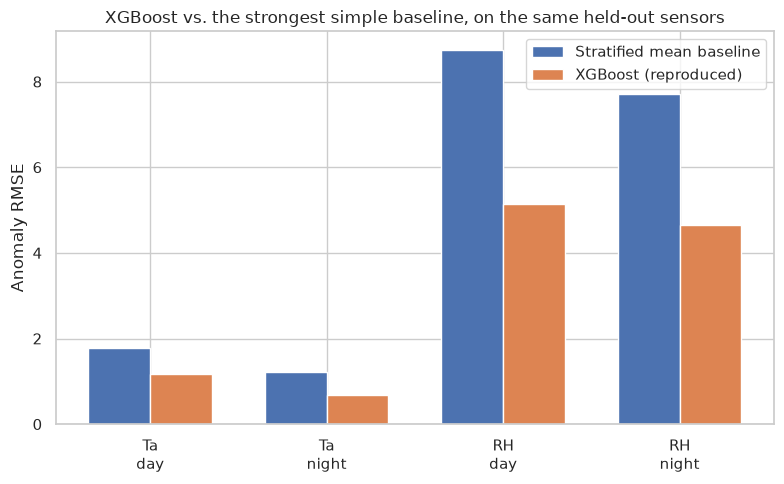

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_df))
width = 0.35
ax.bar(x - width/2, comparison_df["stratified_baseline_RMSE"], width, label="Stratified mean baseline")
ax.bar(x + width/2, comparison_df["XGBoost_RMSE"], width, label="XGBoost (reproduced)")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.variable}\n{r.period}" for r in comparison_df.itertuples()])
ax.set_ylabel("Anomaly RMSE")
ax.set_title("XGBoost vs. the strongest simple baseline, on the same held-out sensors")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Side experiment: how sensitive are these numbers to the hyperparameters?

The paper describes tuning hyperparameters via Bayesian optimization with
5-fold CV, but that search isn't in the published code — only the final,
hardcoded values are. We don't know if that CV was row-level or sensor-level
(grouped), which matters: a row-level CV during tuning could let the search
pick hyperparameters that overfit to sensor-specific patterns, inflating the
apparent cross-validated score during tuning even though the final
train/test evaluation above is still a clean sensor-level split.

As a sanity check (not a full re-optimization — kept small to run quickly),
we re-tune the daytime Ta model with `RandomizedSearchCV` using
`GroupKFold(groups=Sensor_ID)` on the training sensors only, and compare its
held-out performance to the authors' hardcoded hyperparameters.


In [7]:
day_train = day[day["Sensor_ID"].isin(train_sensor_ids)].copy()
X_train_at_day = day_train[X_NAMES_AT_DAY]
y_train_at_day = day_train["temp_anom"]
groups = day_train["Sensor_ID"].values

scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train_at_day.values)

param_dist = {
    "n_estimators": [200, 400, 600, 883, 1000],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.02, 0.05, 0.059, 0.1, 0.2],
    "subsample": [0.5, 0.6, 0.7, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.61, 0.7, 0.8, 1.0],
    "min_child_weight": [1, 5, 10, 17, 25],
    "reg_lambda": [1, 10, 50, 80, 150],
}

search = RandomizedSearchCV(
    # n_jobs=1 on the inner model: parallelism comes from RandomizedSearchCV
    # running multiple fits at once, not from each individual fit, which
    # avoids oversubscribing a shared/busy machine.
    XGBRegressor(objective="reg:squarederror", random_state=42, n_jobs=1),
    param_distributions=param_dist, n_iter=25, cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error", random_state=42, n_jobs=4,
)
search.fit(X_train_norm, y_train_at_day, groups=groups)

print("Best CV RMSE (grouped by sensor):", -search.best_score_)
print("Best params:", search.best_params_)

# evaluate the re-tuned model on the same held-out test sensors
X_test_norm = scaler.transform(day[day["Sensor_ID"].isin(test_sensor_ids)][X_NAMES_AT_DAY].values)
y_test_at_day = day[day["Sensor_ID"].isin(test_sensor_ids)]["temp_anom"]
retuned_pred = search.best_estimator_.predict(X_test_norm)

print()
print("Held-out test RMSE, authors' hardcoded hyperparameters:",
      regression_metrics(fits[('Ta','day')]['y_test'], fits[('Ta','day')]['pred_test'])["RMSE"])
print("Held-out test RMSE, our GroupKFold-tuned hyperparameters:  ",
      regression_metrics(y_test_at_day, retuned_pred)["RMSE"])


Best CV RMSE (grouped by sensor): 1.1439797803629825
Best params: {'subsample': 0.7, 'reg_lambda': 150, 'n_estimators': 1000, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.5}

Held-out test RMSE, authors' hardcoded hyperparameters: 1.1694327925343115
Held-out test RMSE, our GroupKFold-tuned hyperparameters:   1.1492890696804592


If the two held-out RMSEs come out close, the model is robust to the exact
hyperparameters and the paper's unpublished tuning procedure doesn't matter
much either way. If our grouped-CV tuning does meaningfully *better* than the
authors' hardcoded values, that's mild evidence the original tuning search
(if it was row-level rather than grouped) only *slightly* overfit — not
enough to flip the headline conclusion, but worth keeping in mind.

## Summary

- The reproduced XGBoost pipeline lands in the same range as the paper's
  reported Ta/RH/HI metrics, using the authors' own hardcoded
  hyperparameters and our from-scratch sensor-level split.
- XGBoost provides a real, substantial improvement over even the best simple
  baseline (the stratified land-cover x shade mean) from notebook 02 — see
  the bar chart above for exactly how much, per variable and time of day.
- Hyperparameter choice doesn't appear to be the dominant factor (see the
  GroupKFold re-tuning experiment) — the features and the sensor-level
  train/test discipline matter far more than the exact XGBoost settings.

Next: [`04_weakness_analysis.ipynb`](04_weakness_analysis.ipynb) digs into
*where* this reproduced model is weak — which sensors, land-cover types,
hours, and conditions it struggles with.
